In [3]:
import os
import json
import copy
import tqdm
import numpy as np

import torch
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from transformers import RobertaForMaskedLM
from transformers import RobertaTokenizer
from transformers import RobertaConfig

## 超参数和模型参数

In [20]:
data_end = 100
batch_size = 16
epochs = 10
learning_rate = 5e-5
weight_decay = 0.01
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


mlm_probability=0.15
special_tokens_mask=None
prob_replace_mask=0.8
prob_replace_rand=0.1
prob_keep_ori=0.1

vocab_size=181
max_position_embeddings=505
num_attention_heads=12
num_hidden_layers=6
type_vocab_size=1
hidden_dropout_prob=0.1
attention_probs_dropout_prob=0.1
hidden_size=768


In [5]:
# tokenizer = RobertaTokenizer.from_pretrained('models/tokenizer-smiles-roberta')
# smiles ='O1N=C(C(=[C]1)N(=O)=O)Cl'
# tokens = tokenizer.tokenize(smiles)
# print(tokens)

In [6]:
# encode_dict = tokenizer.encode_plus(smiles, max_length=100, padding='max_length', truncation=True)
# print(encode_dict)

## MLM训练数据

In [15]:
def pre_processing_smi(smiles_str, tokenizer,smiles_maxlen=300):
    encode_dict = tokenizer.encode_plus(
        text=smiles_str,  # 输入的smiles字符串
        max_length=smiles_maxlen,  # 300
        padding='max_length',  # 300
        truncation=True)  # 超过最大长度截断处理
    smiles_ids = torch.from_numpy(np.array(encode_dict['input_ids'])).view(1, -1)  # smiles ----> tensor
    smiles_mask = torch.from_numpy(np.array(encode_dict['attention_mask'])).view(1, -1)
    return smiles_ids, smiles_mask
        
class NISTDataset(Dataset):
    def __init__(self, data_end, mlm_probability,special_tokens_mask,prob_replace_mask,prob_replace_rand):
        self.data = []
        self.tokenizer = RobertaTokenizer.from_pretrained('models/tokenizer-smiles-roberta')
        for i in tqdm.tqdm(range(data_end)):
            begin, end = i * 1000 + 1, (i + 1) * 1000
            filename = "data/all_data/train/" + str(begin) + "-" + str(end) + ".json"
            with open(filename, 'r') as fp:  # path在main.py中source_data_path赋值 : data/all_data
                file_data = json.load(fp)
            for tmp_data in file_data:
                input_ids, attention_mask = pre_processing_smi(tmp_data['smiles'], self.tokenizer) # [smiles_ids, smiles_mask]  2维
                inputs, labels = self.mask_tokens(input_ids,mlm_probability,special_tokens_mask,prob_replace_mask,prob_replace_rand)
                
###################### data结构 input_ids, labels, attention_mask ############################################                                                              
                self.data.append((inputs, labels, attention_mask))

                
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        return self.data[idx]
    
    def mask_tokens(self, inputs, mlm_probability,special_tokens_mask,prob_replace_mask,prob_replace_rand):
        """
        :param inputs: (seq_len)
        :return: (seq_len), (seq_len)
        """
        labels = inputs.clone()
        # 生成一个全为0.15 的矩阵，维度和inputs的大小一样
        probability_matrix = torch.full(labels.shape, mlm_probability)
        # 这里的spcial_tokens指的是cls，sep,pad等，special_tokens_mask的维度和inputs一样，
        # 特殊token的位置是true，其他位置是false
        if special_tokens_mask is None:
            # 
            special_tokens_mask = [
                self.tokenizer.get_special_tokens_mask(val, already_has_special_tokens=True) for val in labels.tolist()
            ]
            special_tokens_mask = torch.tensor(special_tokens_mask, dtype=torch.bool)
        else:
            special_tokens_mask = special_tokens_mask.bool()
        # masked_fill_函数的作用是会根据special_tokens_mask中true的位置，将probability_matrix中对于的位置置为0
        # 前面special_tokens_mask已经将cls等特殊字符的位置置为true,也就是通过将probability_matrix中特殊字符的位置置0，从而
        # 不会mask掉特殊字符。

        probability_matrix.masked_fill_(special_tokens_mask, value=0.0)
        # Bert是将句子中15%的词随机mask掉，也就是每个词有15%的概率被mask掉（1），有85%的概率不被mask掉（0），
        # 因此可以建模为伯努利分布，参数p=0.15，然后通过bernoulli函数生成一个mask矩阵，维度和inputs一样，
        masked_indices = torch.bernoulli(probability_matrix).bool()
        labels[~masked_indices] = -100  # We only compute loss on masked tokens

        # 80% of the time, we replace masked input tokens with tokenizer.mask_token ([MASK])
        indices_replaced = torch.bernoulli(torch.full(labels.shape, prob_replace_mask)).bool() & masked_indices
        inputs[indices_replaced] = self.tokenizer.convert_tokens_to_ids(self.tokenizer.mask_token)

        # 10% of the time, we replace masked input tokens with random word
        current_prob = prob_replace_rand / (1 - prob_replace_mask)
        indices_random = torch.bernoulli(torch.full(labels.shape, current_prob)).bool() & masked_indices & ~indices_replaced
        random_words = torch.randint(len(self.tokenizer), labels.shape).int()
        inputs[indices_random] = random_words[indices_random]

        # The rest of the time (10% of the time) we keep the masked input tokens unchanged
        return inputs, labels



In [16]:
nistdataloader = DataLoader(NISTDataset(data_end, mlm_probability,special_tokens_mask,prob_replace_mask,prob_replace_rand), batch_size, shuffle=True, drop_last=True)

100%|██████████| 100/100 [00:45<00:00,  2.20it/s]


## 定义模型

In [17]:
config = RobertaConfig(vocab_size=vocab_size,
                       max_position_embeddings=max_position_embeddings,
                       num_attention_heads=num_attention_heads,
                       num_hidden_layers=num_hidden_layers,
                       type_vocab_size=type_vocab_size,
                       hidden_dropout_prob=hidden_dropout_prob,
                       attention_probs_dropout_prob=attention_probs_dropout_prob)
roberta_mlm_model = RobertaForMaskedLM(config)

## 训练函数

In [33]:
def train(model, device, train_dataloader):
    """
    训练
    :param model: nn.Module
    :param train_dataloader: DataLoader
    :param config: Config
    """
    # assert device.startswith('cuda') or device == 'cpu', ValueError("Invalid device.")
    # device = torch.device(device)
    
    model.to(device)
    
    if not len(train_dataloader):
        raise EOFError("Empty train_dataloader.")
        
    param_optimizer = list(model.named_parameters())
    no_decay = ["bias", "LayerNorm.bias", "LayerNorm.weight"]
    optimizer_grouped_parameters = [
        {"params": [p for n, p in param_optimizer if not any(nd in n for nd in no_decay)], "weight_decay": 0.01},
        {"params": [p for n, p in param_optimizer if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
    
    optimizer = AdamW(params=optimizer_grouped_parameters, lr=learning_rate, weight_decay=weight_decay)
    
    for cur_epc in tqdm.tqdm(range(int(epochs)), desc="Epoch"):
        training_loss = 0
        print("Epoch: {}".format(cur_epc+1))
        model.train()
        for step, batch in enumerate(tqdm.tqdm(train_dataloader, desc='Step')):
            optimizer.zero_grad()
            input_ids, labels, attention_mask = batch
            print(input_ids.shape, labels.shape, attention_mask.shape)
            input_ids = input_ids.squeeze(0).squeeze(1).to(device)
            labels = labels.squeeze(0).squeeze(1).to(device)
            attention_mask = attention_mask.squeeze(0).squeeze(1).to(device)
            loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            training_loss += loss.item()
        print("Training loss: ", training_loss)


In [35]:
train(model=roberta_mlm_model, device=device, train_dataloader=nistdataloader)

Epoch:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1


Epoch:   0%|          | 0/10 [00:00<?, ?it/s]


torch.Size([16, 1, 300]) torch.Size([16, 1, 300]) torch.Size([16, 1, 300])


RuntimeError: CUDA out of memory. Tried to allocate 16.00 MiB (GPU 0; 24.00 GiB total capacity; 2.88 GiB already allocated; 19.04 GiB free; 3.07 GiB reserved in total by PyTorch) If reserved memory is >> allocated memory try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

In [ ]:
import datetime
save_path = 'models/roberta_pretrain_model/'
model_suffix = datetime.datetime.now().strftime("%Y-%m-%d_%H%M%S")

In [ ]:
torch.save(roberta_mlm_model.roberta.embeddings.state_dict(), os.path.join(save_path, 'bert_mlm_ep_{}_eb'.format(config.epochs) + model_suffix + '.pth'))
torch.save(roberta_mlm_model.roberta.encoder.state_dict(), os.path.join(config.save_path, 'bert_mlm_ep_{}_ec'.format(config.epochs)+ model_suffix + '.pth'))


# 测试smiles数据增强

In [4]:
import rdkit
from rdkit import Chem
import numpy as np

In [5]:
def randomize_smile(sml):
    """Function that randomizes a SMILES sequnce. This was adapted from the
    implemetation of E. Bjerrum 2017, SMILES Enumeration as Data Augmentation
    for Neural Network Modeling of Molecules.
    Args:
        sml: SMILES sequnce to randomize.
    Return:
        randomized SMILES sequnce or
        nan if SMILES is not interpretable.
    """
    try:
        m = Chem.MolFromSmiles(sml)
        ans = list(range(m.GetNumAtoms()))
        np.random.shuffle(ans)
        nm = Chem.RenumberAtoms(m, ans)
        return Chem.MolToSmiles(nm, canonical=False)
    except:
        return float('nan')

In [6]:
smiles_list = ['c1cc(-c2cc(-c3ccncc3)nc(-c3ccncc3)c2)ccn1']
augmented_smiles = set()
for smiles in smiles_list:
    for _ in range(5):
        augmented_smiles.add(randomize_smile(smiles))

In [7]:
print(augmented_smiles)

{'c1(-c2ccncc2)cc(-c2ccncc2)cc(-c2ccncc2)n1', 'c1c(-c2ccncc2)nc(-c2ccncc2)cc1-c1ccncc1', 'c1cc(-c2cc(-c3ccncc3)cc(-c3ccncc3)n2)ccn1', 'c1cnccc1-c1nc(-c2ccncc2)cc(-c2ccncc2)c1'}


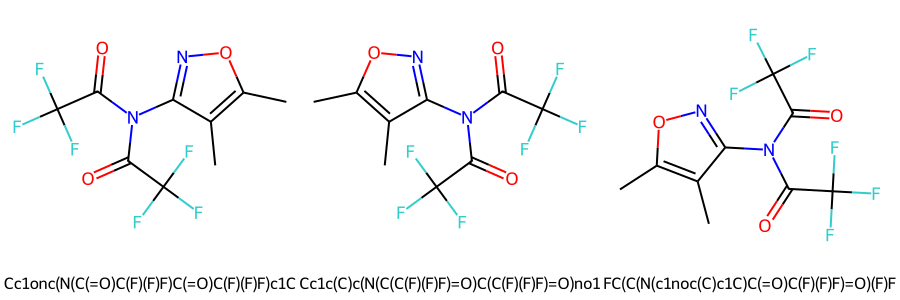

In [11]:
# 绘制分子图
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import AllChem

smiles0 = 'Cc1onc(N(C(=O)C(F)(F)F)C(=O)C(F)(F)F)c1C'
smiles1 = 'Cc1c(C)c(N(C(C(F)(F)F)=O)C(C(F)(F)F)=O)no1'
smiles2 = 'FC(C(N(c1noc(C)c1C)C(=O)C(F)(F)F)=O)(F)F'

m0 = Chem.MolFromSmiles(smiles0)
m1 = Chem.MolFromSmiles(smiles1)
m2 = Chem.MolFromSmiles(smiles2)

Draw.MolsToGridImage([m0, m1, m2], molsPerRow=3, subImgSize=(300, 300), legends=[smiles0, smiles1, smiles2])




# 对nist23训练集数据增强，保存

In [4]:
import os
import json
import rdkit
from rdkit import Chem
import numpy as np
import tqdm

data_dir = 'data/all_data/train23'
save_dir = 'data/all_data/augmentation_x10_train23'

In [5]:
def randomize_smile(sml):
    """Function that randomizes a SMILES sequnce. This was adapted from the
    implemetation of E. Bjerrum 2017, SMILES Enumeration as Data Augmentation
    for Neural Network Modeling of Molecules.
    Args:
        sml: SMILES sequnce to randomize.
    Return:
        randomized SMILES sequnce or
        nan if SMILES is not interpretable.
    """
    try:
        m = Chem.MolFromSmiles(sml)
        ans = list(range(m.GetNumAtoms()))
        np.random.shuffle(ans)
        nm = Chem.RenumberAtoms(m, ans)
        return Chem.MolToSmiles(nm, canonical=False)
    except:
        return print(sml)

In [6]:
path_list = os.listdir(data_dir)  # 文件夹中的文件列表
path_list.sort(key=lambda x: int(x.split('-')[0]))  # 按名称的数字排序
num = 0
for i in tqdm.tqdm(range(0, len(path_list))):  # 按顺序逐次遍历文件夹下的文件
    inputfile = os.path.join(data_dir, path_list[i])  # 对应文件夹下的某份文件
    with open(inputfile, 'r') as f:
        augmented_smiles = set()
        data = json.load(f)
        smiles_list = [d['smiles'] for d in data]
        for smiles in smiles_list:
            augmented_smiles.add(smiles)
            for _ in range(10):
                augmented_smiles.add(randomize_smile(smiles))
        augmented_smiles = list(augmented_smiles)
        num += len(augmented_smiles)
    with open(os.path.join(save_dir, path_list[i]), 'w') as f:
        json.dump(augmented_smiles, f, indent=4)
print(num)

100%|██████████| 70/70 [11:52<00:00, 10.18s/it]

3267501
